In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# file_ids = [0]
plot_id = 0

bhl_selection = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']

dims = 4
dims_preca = 5

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, file_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = markers[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	markers[i] = markers[i][mask]
	states[i] = states[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
#markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [5]:
for idx in range(len(states)):
	states[idx] = states[idx].reindex(columns=['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move'])

In [6]:
plot_idx = file_ids.index(plot_id)

In [7]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[s[bhl_selection] for s in states],
																	scale=(False, False),
																	n_cv=dims, n_pc=dims_preca)

In [8]:
save = True

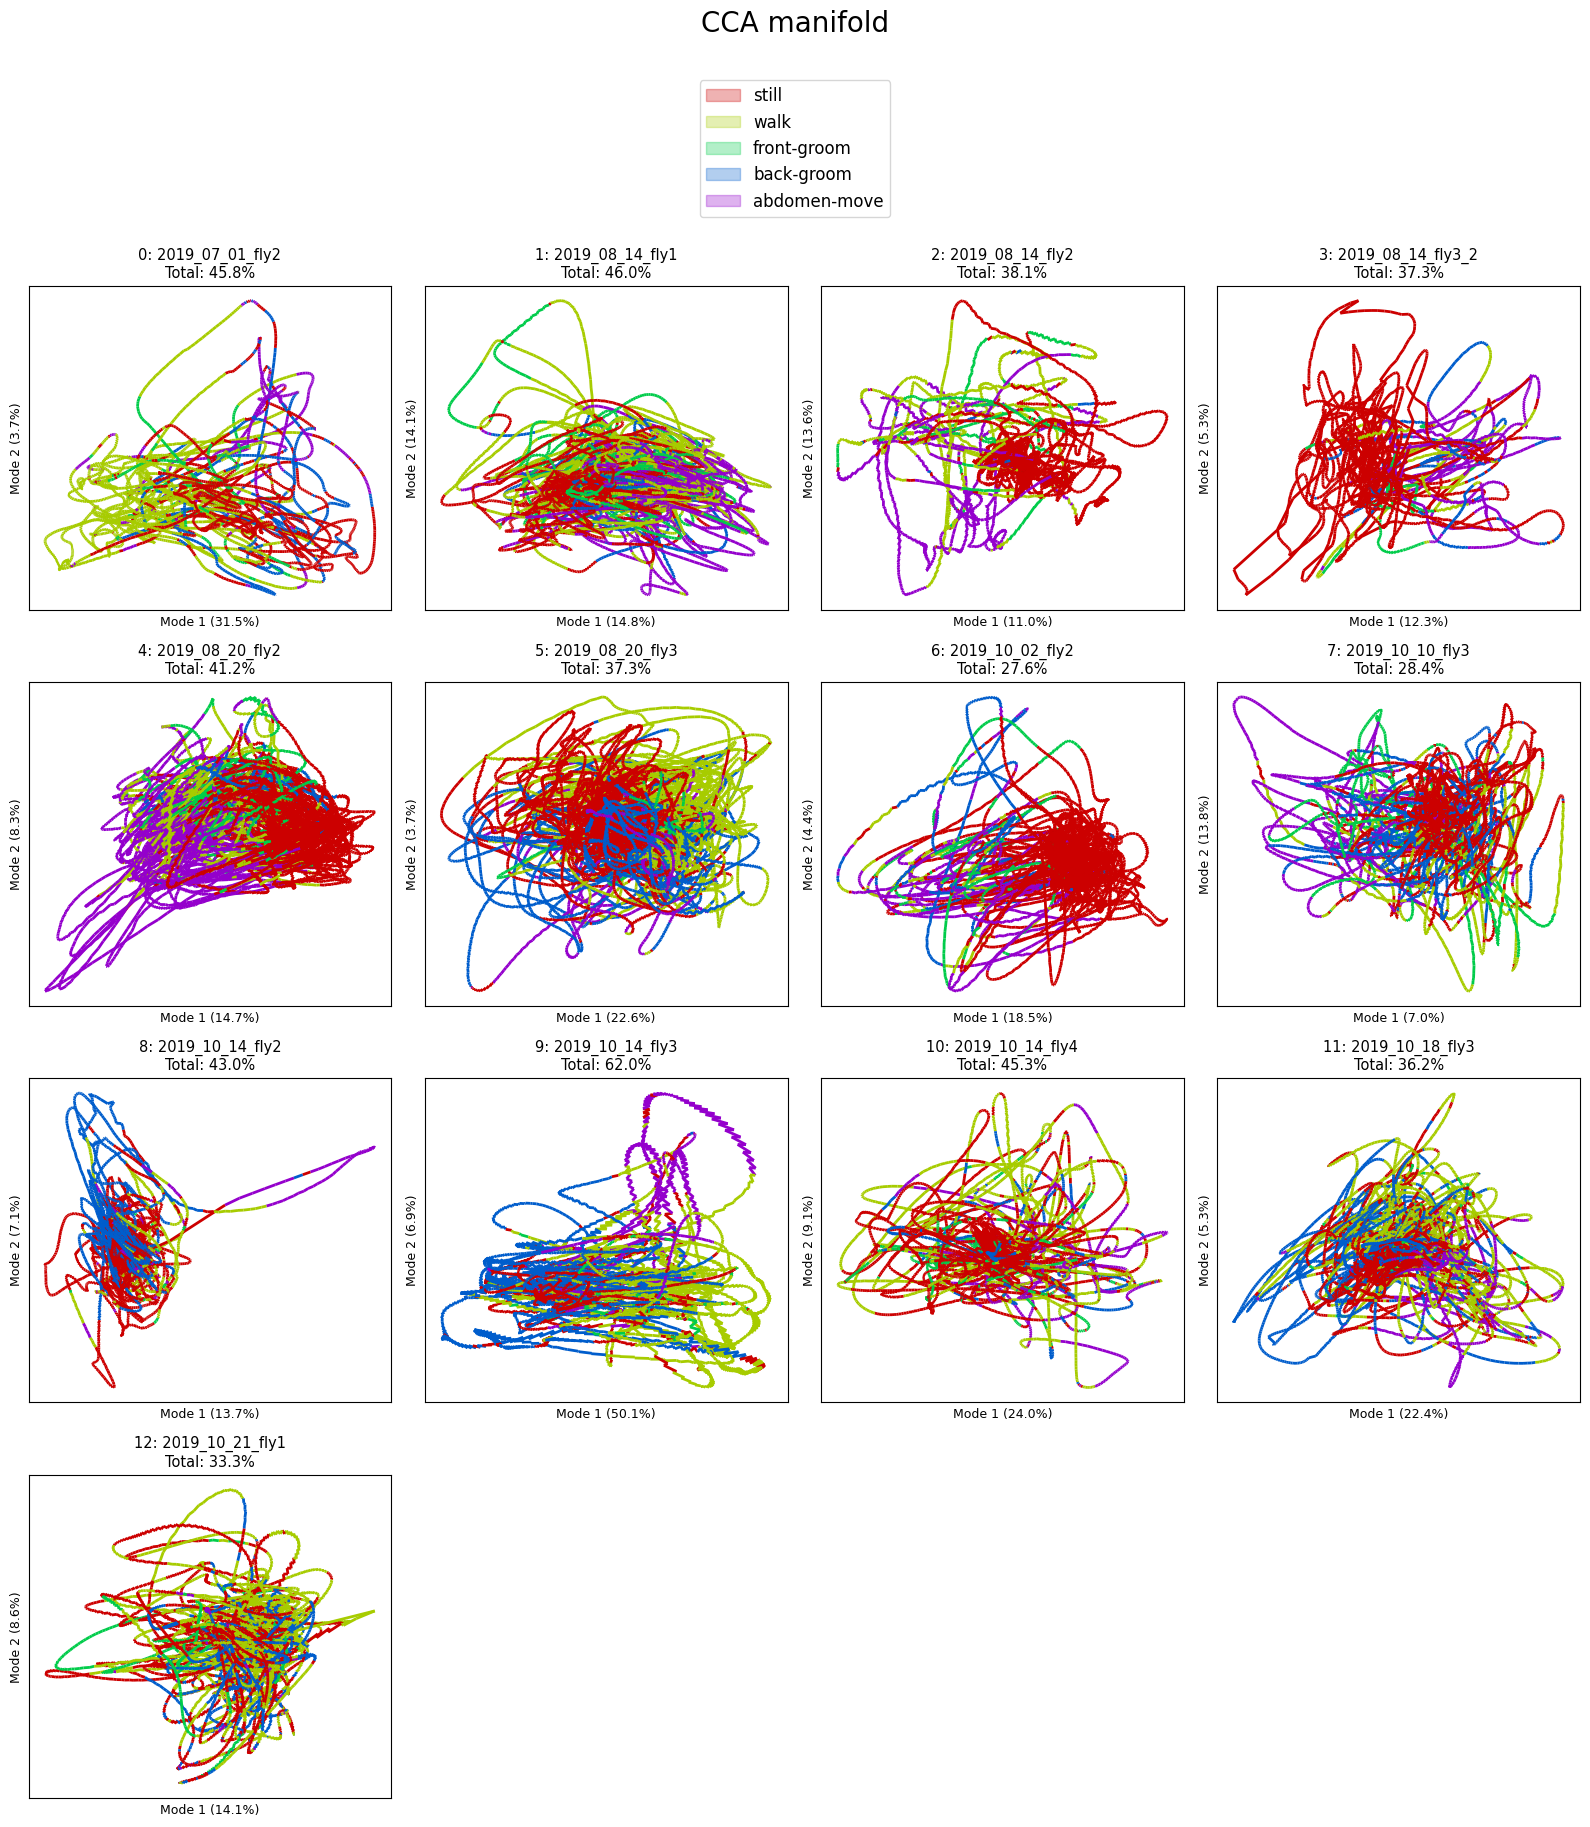

40.1%


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx for vx in vars_expl_mans], None,
						  title='CCA manifold', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA' if save else None)

In [10]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 							 title='CCA manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)

In [11]:
for file_id in file_ids:
	corrs = [
		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
	]
	print(f'{file_id}: {filenames[file_ids.index(file_id)]}')
	for i, corr in enumerate(corrs):
		print(f'\tCV{i}: {corr:.2f}')

0: 2019_07_01_fly2
	CV0: 0.64
	CV1: 0.39
	CV2: 0.18
	CV3: 0.03
1: 2019_08_14_fly1
	CV0: 0.47
	CV1: 0.29
	CV2: 0.18
	CV3: 0.14
2: 2019_08_14_fly2
	CV0: 0.61
	CV1: 0.43
	CV2: 0.15
	CV3: 0.05
3: 2019_08_14_fly3_2
	CV0: 0.63
	CV1: 0.22
	CV2: 0.11
	CV3: 0.07
4: 2019_08_20_fly2
	CV0: 0.77
	CV1: 0.36
	CV2: 0.09
	CV3: 0.06
5: 2019_08_20_fly3
	CV0: 0.47
	CV1: 0.33
	CV2: 0.06
	CV3: 0.03
6: 2019_10_02_fly2
	CV0: 0.71
	CV1: 0.28
	CV2: 0.06
	CV3: 0.03
7: 2019_10_10_fly3
	CV0: 0.53
	CV1: 0.32
	CV2: 0.28
	CV3: 0.16
8: 2019_10_14_fly2
	CV0: 0.48
	CV1: 0.41
	CV2: 0.19
	CV3: 0.06
9: 2019_10_14_fly3
	CV0: 0.65
	CV1: 0.48
	CV2: 0.17
	CV3: 0.04
10: 2019_10_14_fly4
	CV0: 0.36
	CV1: 0.19
	CV2: 0.13
	CV3: 0.04
11: 2019_10_18_fly3
	CV0: 0.45
	CV1: 0.27
	CV2: 0.12
	CV3: 0.04
12: 2019_10_21_fly1
	CV0: 0.36
	CV1: 0.20
	CV2: 0.16
	CV3: 0.11


In [12]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 2.37185867e-05  1.04967881e-05 -1.72755488e-06 ...  8.11570176e-06
  8.54363303e-06  1.02351925e-05]
[-1.80297369e-06  3.02665198e-05 -5.31332765e-06 ... -1.50346096e-08
  2.09294611e-05 -2.17224570e-05]
[-2.47045681e-05  9.38844621e-05  1.08397257e-04 ...  1.61152178e-05
  1.28445804e-05  7.75366618e-06]
[-6.99085150e-05 -3.36374042e-05  7.87121767e-05 ... -1.14272440e-05
 -7.04881950e-05  5.21399589e-05]
[-2.10522827e-04 -1.29863583e-04 -1.97200572e-04 -2.10153632e-04
 -2.57761756e-04 -1.51589393e-04 -2.08322665e-04 -1.41747443e-04
 -3.77318334e-04 -1.03474285e-04 -2.57781011e-04 -3.37957808e-04
 -2.16973836e-04 -1.20542404e-04 -1.30678219e-04 -1.10101478e-04
  1.62759545e-05 -1.73857437e-04 -7.77820746e-05 -7.42820953e-05
 -3.17062024e-04 -3.12328765e-04 -2.77342558e-04 -1.59463623e-04
 -5.95768371e-05 -1.50942274e-04 -4.95224330e-05 -1.18319521e-04
 -2.04051159e-04 -2.24603556e-04 -1.55857306e-04 -1.27883227e-04
 -1.89646775e-04 -1.21821666e-04 -2.46636254e-04 -5.63355553e-05
 -8

In [13]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

[-5.97536612e-19  5.97536612e-20  3.28645136e-19 ...  1.19507322e-19
  2.98768306e-19  1.87409210e-19]
[-2.32714568e-20  1.51264469e-19 -1.01812623e-20 ... -2.03625247e-20
 -2.50168160e-19 -4.36339815e-20]
[ 2.89459790e-20 -6.58521022e-19  2.74986801e-19 ...  1.26638658e-20
 -4.88463396e-20 -2.60513811e-19]
[ 9.91624709e-20  1.38827459e-19 -7.93299768e-20 ... -1.98324942e-20
  4.16482378e-19 -1.78492448e-19]
[ 8.22082950e-20 -2.36348848e-19 -6.71367743e-19  2.53475576e-19
 -1.01390231e-18 -1.47632397e-18  2.44912212e-18  1.08925991e-18
 -2.34293641e-18  9.59096776e-20 -3.31573457e-18  1.38383963e-18
 -1.21257235e-18  5.96010139e-19 -1.89421613e-18 -1.88394009e-19
  1.31875807e-19  1.37013825e-19  9.29125001e-19 -4.47007604e-19
  2.60326268e-18 -1.75377696e-18  2.19222120e-18  1.61676314e-18
  5.75458065e-19 -1.89421613e-18 -6.50815669e-20 -1.22627373e-18
 -1.23312443e-19 -1.26737788e-18 -3.08281106e-19 -9.24843319e-19
  3.42534563e-20 -2.80878341e-19 -1.32218341e-18  2.74027650e-19
  6

In [14]:
# traces_manifolds_indices = [np.argsort(xloads_cca_man[0, :]) for xloads_cca_man in loads_cca_man]
#
# traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
#
# traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]
#
# traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]